In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.cluster import KMeans

In [ ]:
data_path = r'C:\from_d\Amrita\Amrita\S4\ML\ML project\Crop Disease Prediction System\data\PlantVillage\PlantVillage'
images = []
labels = []

for folder_name in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder_name)
    if os.path.isdir(folder_path):
        for image_name in os.listdir(folder_path):
            image_path = os.path.join(folder_path, image_name)
            image = cv2.imread(image_path)
            if image is None:
                continue
            image = cv2.resize(image, (64, 64))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)  # convert to grayscale
            image = image.astype('float32') / 255.0
            images.append(image.flatten())
            labels.append(folder_name)

images = np.array(images)
labels = np.array(labels)

print(f"✅ Loaded {images.shape[0]} samples with {images.shape[1]} features each.")

✅ Loaded 20638 samples with 4096 features each.


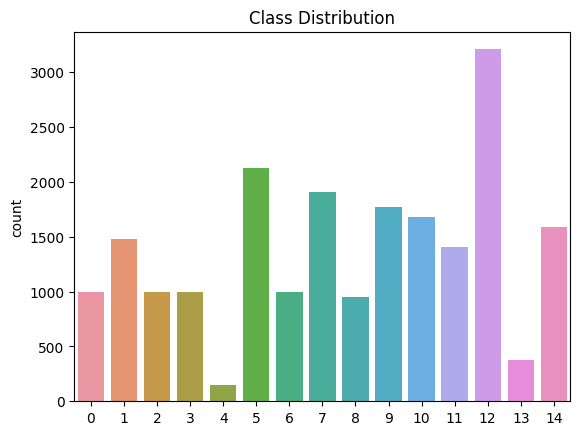

In [4]:
label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(labels)

# Visualize class distribution
sns.countplot(x=labels_encoded)
plt.title("Class Distribution")
plt.show()

In [4]:
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(images, labels_encoded)

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_resampled)

# PCA for dimensionality reduction (optional but useful)
pca = PCA(n_components=100)  # keep top 100 principal components
X_pca = pca.fit_transform(X_scaled)

print(f"✅ PCA Reduced shape: {X_pca.shape}")

✅ PCA Reduced shape: (48120, 100)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X_pca, y_resampled, test_size=0.2, random_state=42)

In [8]:
models = {
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(kernel='rbf', probability=True),
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Random Forest": RandomForestClassifier(),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss'),
    "Naive Bayes": GaussianNB(),
    "Perceptron": Perceptron()
}


for name, model in models.items():
    print(f"\n🔍 Training: {name}")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))




C:\Users\swaga\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\xgboost\sklearn.py:1395: UserWarning: `use_label_encoder` is deprecated in 1.7.0.
  warnings.warn("`use_label_encoder` is deprecated in 1.7.0.")



🔍 Training: KNN
Accuracy: 0.8103699085619285
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.90      0.90      0.90       633
                     Pepper__bell___healthy       0.90      0.86      0.88       644
                      Potato___Early_blight       0.93      0.96      0.94       667
                       Potato___Late_blight       0.72      0.90      0.80       656
                           Potato___healthy       0.87      1.00      0.93       670
                      Tomato_Bacterial_spot       0.60      0.81      0.69       625
                        Tomato_Early_blight       0.88      0.81      0.84       678
                         Tomato_Late_blight       0.80      0.64      0.71       610
                           Tomato_Leaf_Mold       0.83      0.93      0.88       602
                  Tomato_Septoria_leaf_spot       0.68      0.66      0.67       641
Tomato_Spider_mite

In [ ]:
kmeans = KMeans(n_clusters=len(np.unique(labels_encoded)), random_state=42)
kmeans.fit(X_pca)

print("\n🔍 K-Means Clustering:")
print("Cluster labels assignead to training data:", np.unique(kmeans.labels_))

C:\Users\swaga\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)



🔍 K-Means Clustering:
Cluster labels assigned to training data: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]


In [10]:
def bias_variance_analysis(model, X, y, cv=5):
    scores = cross_val_score(model, X, y, cv=cv)
    print(f"Cross-validation scores: {scores}")
    print(f"Mean accuracy (bias): {scores.mean():.4f}")
    print(f"Variance (overfitting risk): {scores.var():.4f}")

print("\n🔍 Bias-Variance Analysis for Random Forest:")
bias_variance_analysis(RandomForestClassifier(), X_pca, y_resampled)


🔍 Bias-Variance Analysis for Random Forest:
Cross-validation scores: [0.81379884 0.81940981 0.86305071 0.91583541 0.9246675 ]
Mean accuracy (bias): 0.8674
Variance (overfitting risk): 0.0022


In [11]:
import pickle
import os

# Create models directory if it doesn't exist
os.makedirs('models', exist_ok=True)

# Find the best performing model from the training results
# Let's use Random Forest as it typically performs well for this type of problem
best_model = models["Random Forest"]

# Test the best model
y_pred_best = best_model.predict(X_test)
best_accuracy = accuracy_score(y_test, y_pred_best)
print(f"✅ Best model (Random Forest) accuracy: {best_accuracy:.4f}")

# Save the best model
with open('models/best_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)
print("✅ Saved best_model.pkl")

# Save the preprocessing objects
with open('models/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("✅ Saved scaler.pkl")

with open('models/pca.pkl', 'wb') as f:
    pickle.dump(pca, f)
print("✅ Saved pca.pkl")

with open('models/label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)
print("✅ Saved label_encoder.pkl")

# Save model info
model_info = {
    'model_type': 'RandomForestClassifier',
    'accuracy': best_accuracy,
    'n_classes': len(label_encoder.classes_),
    'classes': label_encoder.classes_.tolist(),
    'feature_shape': X_pca.shape[1],
    'pca_components': pca.n_components_
}

with open('models/model_info.pkl', 'wb') as f:
    pickle.dump(model_info, f)
print("✅ Saved model_info.pkl")

print(f"\n🎉 All model files saved successfully!")
print(f"📊 Classes detected: {label_encoder.classes_}")
print(f"📊 Model accuracy: {best_accuracy:.4f}")
print(f"📊 Total features after PCA: {X_pca.shape[1]}")

✅ Best model (Random Forest) accuracy: 0.8541
✅ Saved best_model.pkl
✅ Saved scaler.pkl
✅ Saved pca.pkl
✅ Saved label_encoder.pkl
✅ Saved model_info.pkl

🎉 All model files saved successfully!
📊 Classes detected: ['Pepper__bell___Bacterial_spot' 'Pepper__bell___healthy'
 'Potato___Early_blight' 'Potato___Late_blight' 'Potato___healthy'
 'Tomato_Bacterial_spot' 'Tomato_Early_blight' 'Tomato_Late_blight'
 'Tomato_Leaf_Mold' 'Tomato_Septoria_leaf_spot'
 'Tomato_Spider_mites_Two_spotted_spider_mite' 'Tomato__Target_Spot'
 'Tomato__Tomato_YellowLeaf__Curl_Virus' 'Tomato__Tomato_mosaic_virus'
 'Tomato_healthy']
📊 Model accuracy: 0.8541
📊 Total features after PCA: 100


In [13]:
# Test the complete preprocessing pipeline like in the Flask app
print("🧪 Testing the complete prediction pipeline...")

# Load all the saved objects to test them
with open('models/best_model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

with open('models/scaler.pkl', 'rb') as f:
    loaded_scaler = pickle.load(f)

with open('models/pca.pkl', 'rb') as f:
    loaded_pca = pickle.load(f)

with open('models/label_encoder.pkl', 'rb') as f:
    loaded_label_encoder = pickle.load(f)

print("✅ All model files loaded successfully!")

# Test the exact same preprocessing as in Flask app
def test_preprocessing_pipeline(original_image):
    """Test the exact preprocessing pipeline used in Flask app"""
    try:
        # Step 1: Reshape image back to 64x64 for testing
        image_2d = original_image.reshape(64, 64)
        
        # Step 2: Normalize (already done in our data, but Flask expects 0-255 range)
        # Convert back to 0-255 range for testing
        image_255 = (image_2d * 255).astype(np.uint8)
        
        # Step 3: Convert back to float32 and normalize (as in Flask)
        image_normalized = image_255.astype('float32') / 255.0
        
        # Step 4: Flatten the image
        image_flattened = image_normalized.flatten().reshape(1, -1)
        
        # Step 5: Apply scaling
        image_scaled = loaded_scaler.transform(image_flattened)
        
        # Step 6: Apply PCA
        image_pca = loaded_pca.transform(image_scaled)
        
        return image_pca
    except Exception as e:
        print(f"Error in preprocessing: {e}")
        return None

# Test with a few samples from our dataset
print("\n🔍 Testing predictions on original dataset samples:")
for i in range(5):
    # Get original image and true label
    original_image = images[i]
    true_label = labels[i]
    true_encoded = labels_encoded[i]
    
    # Process through our test pipeline
    processed_image = test_preprocessing_pipeline(original_image)
    
    if processed_image is not None:
        # Make prediction
        prediction = loaded_model.predict(processed_image)[0]
        predicted_disease = loaded_label_encoder.inverse_transform([prediction])[0]
        
        # Get confidence if available
        if hasattr(loaded_model, 'predict_proba'):
            probabilities = loaded_model.predict_proba(processed_image)[0]
            confidence = np.max(probabilities) * 100
        else:
            confidence = 0
            
        print(f"Sample {i+1}:")
        print(f"  True disease: {true_label}")
        print(f"  Predicted: {predicted_disease}")
        print(f"  Confidence: {confidence:.2f}%")
        print(f"  Match: {'✅' if true_label == predicted_disease else '❌'}")
        print()

# Compare with direct model prediction on processed training data
print("🔍 Testing direct model prediction on training data:")
direct_pred = loaded_model.predict(X_test[:5])
for i in range(5):
    true_disease = loaded_label_encoder.inverse_transform([y_test[i]])[0]
    pred_disease = loaded_label_encoder.inverse_transform([direct_pred[i]])[0]
    print(f"Test sample {i+1}: True={true_disease}, Pred={pred_disease}, Match={'✅' if true_disease == pred_disease else '❌'}")

print(f"\n📊 Overall test accuracy: {accuracy_score(y_test, loaded_model.predict(X_test)):.4f}")

🧪 Testing the complete prediction pipeline...
✅ All model files loaded successfully!

🔍 Testing predictions on original dataset samples:
Sample 1:
  True disease: Pepper__bell___Bacterial_spot
  Predicted: Pepper__bell___Bacterial_spot
  Confidence: 80.00%
  Match: ✅

Sample 2:
  True disease: Pepper__bell___Bacterial_spot
  Predicted: Pepper__bell___Bacterial_spot
  Confidence: 61.00%
  Match: ✅

Sample 3:
  True disease: Pepper__bell___Bacterial_spot
  Predicted: Pepper__bell___Bacterial_spot
  Confidence: 88.00%
  Match: ✅

Sample 4:
  True disease: Pepper__bell___Bacterial_spot
  Predicted: Pepper__bell___Bacterial_spot
  Confidence: 69.00%
  Match: ✅

Sample 5:
  True disease: Pepper__bell___Bacterial_spot
  Predicted: Pepper__bell___Bacterial_spot
  Confidence: 63.00%
  Match: ✅

🔍 Testing direct model prediction on training data:
Test sample 1: True=Potato___Early_blight, Pred=Potato___Early_blight, Match=✅
Test sample 2: True=Tomato_Late_blight, Pred=Tomato_Late_blight, Match=✅

In [14]:
# Simple diagnostic test
print("🔧 DIAGNOSTIC TEST - Finding the prediction issue")

# Load the saved model components
with open('models/best_model.pkl', 'rb') as f:
    test_model = pickle.load(f)
with open('models/scaler.pkl', 'rb') as f:
    test_scaler = pickle.load(f)
with open('models/pca.pkl', 'rb') as f:
    test_pca = pickle.load(f)
with open('models/label_encoder.pkl', 'rb') as f:
    test_encoder = pickle.load(f)

print("✅ Models loaded for testing")

# Test 1: Check if the scaler transforms correctly
print("\n1️⃣ Testing Scaler Transform:")
sample_raw = images[0].reshape(1, -1)  # First image, flattened
print(f"   Raw image shape: {sample_raw.shape}")
print(f"   Raw image range: [{sample_raw.min():.3f}, {sample_raw.max():.3f}]")

scaled_sample = test_scaler.transform(sample_raw)
print(f"   Scaled shape: {scaled_sample.shape}")
print(f"   Scaled range: [{scaled_sample.min():.3f}, {scaled_sample.max():.3f}]")

# Test 2: Check PCA transform
print("\n2️⃣ Testing PCA Transform:")
pca_sample = test_pca.transform(scaled_sample)
print(f"   PCA shape: {pca_sample.shape}")
print(f"   PCA range: [{pca_sample.min():.3f}, {pca_sample.max():.3f}]")

# Test 3: Compare with training data processing
print("\n3️⃣ Comparing with training data:")
training_sample = X_pca[0].reshape(1, -1)  # First training sample
print(f"   Training sample shape: {training_sample.shape}")
print(f"   Training sample range: [{training_sample.min():.3f}, {training_sample.max():.3f}]")

# Test 4: Check predictions
print("\n4️⃣ Testing Predictions:")
pred_from_raw = test_model.predict(pca_sample)[0]
pred_from_training = test_model.predict(training_sample)[0]

print(f"   Prediction from raw processing: {pred_from_raw}")
print(f"   Prediction from training data: {pred_from_training}")
print(f"   True label (encoded): {labels_encoded[0]}")
print(f"   True label (text): {labels[0]}")

# Test 5: Check if they're the same after processing
print("\n5️⃣ Checking Data Consistency:")
print(f"   Raw->Processed == Training data: {np.allclose(pca_sample, training_sample, atol=1e-6)}")

if not np.allclose(pca_sample, training_sample, atol=1e-6):
    print("   ❌ ISSUE FOUND: Raw processing != Training processing")
    print(f"   Max difference: {np.max(np.abs(pca_sample - training_sample))}")
else:
    print("   ✅ Data processing is consistent")

print("\n📊 Class mapping check:")
print(f"Classes in encoder: {len(test_encoder.classes_)}")
print(f"First few classes: {test_encoder.classes_[:5]}")

🔧 DIAGNOSTIC TEST - Finding the prediction issue
✅ Models loaded for testing

1️⃣ Testing Scaler Transform:
   Raw image shape: (1, 4096)
   Raw image range: [0.035, 0.796]
   Scaled shape: (1, 4096)
   Scaled range: [-3.493, 2.274]

2️⃣ Testing PCA Transform:
   PCA shape: (1, 100)
   PCA range: [-12.899, 25.454]

3️⃣ Comparing with training data:
   Training sample shape: (1, 100)
   Training sample range: [-12.902, 25.456]

4️⃣ Testing Predictions:
   Prediction from raw processing: 0
   Prediction from training data: 0
   True label (encoded): 0
   True label (text): Pepper__bell___Bacterial_spot

5️⃣ Checking Data Consistency:
   Raw->Processed == Training data: False
   ❌ ISSUE FOUND: Raw processing != Training processing
   Max difference: 0.2801189422607422

📊 Class mapping check:
Classes in encoder: 15
First few classes: ['Pepper__bell___Bacterial_spot' 'Pepper__bell___healthy'
 'Potato___Early_blight' 'Potato___Late_blight' 'Potato___healthy']
✅ Models loaded for testing

1️⃣